In [1]:
import scipy
import matplotlib.pyplot as plt
import numpy as np
import pyvoro2
from pyvoro2.viz3d import view_tessellation
from skspatial.objects import Plane
import tqdm

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Times New Roman'

In [2]:
microstructure_1000_seeds_and_oris = np.loadtxt("./microstructure_seeds/rolled_copper_texture_orientations_from_MTEX_random_seeds.csv", delimiter = ",")
microstructure_1000_seeds = microstructure_1000_seeds_and_oris[:,:3]
microstructure_1000_seeds_xy = microstructure_1000_seeds_and_oris[:,:2]

In [3]:
microstructure_1000_seeds, microstructure_1000_seeds*1000

(array([[6.73913313e-05, 8.45377301e-05, 7.60904978e-04],
        [3.23241352e-04, 9.25471881e-04, 8.18574909e-04],
        [6.64322277e-04, 1.33284971e-04, 6.84291554e-04],
        ...,
        [1.19820162e-04, 9.19792527e-04, 8.91724346e-04],
        [4.00909121e-04, 4.10943795e-04, 6.36918067e-04],
        [3.75127189e-04, 3.50732559e-04, 6.64585036e-04]], shape=(1000, 3)),
 array([[0.06739133, 0.08453773, 0.76090498],
        [0.32324135, 0.92547188, 0.81857491],
        [0.66432228, 0.13328497, 0.68429155],
        ...,
        [0.11982016, 0.91979253, 0.89172435],
        [0.40090912, 0.41094379, 0.63691807],
        [0.37512719, 0.35073256, 0.66458504]], shape=(1000, 3)))

# PyVoro2

In [38]:
points = np.random.default_rng(0).uniform(-1.5, 1.5, size=(10, 3))
box = pyvoro2.Box(((-2, 2), (-2, 2), (-2, 2)))
result = pyvoro2.compute(points, domain=box, mode='standard')

view_tessellation(
    result.cells,
    domain=box,
    show_vertices=False,
)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [49]:
# Example
cell = pyvoro2.PeriodicCell(
    vectors=(
        (10.0, 0.0, 0.0),
        (0.0, 10.0, 0.0),
        (0.0, 0.0, 10.0),
    )
)

pts_pbc = np.array(
    [
        [1.0, 1.0, 1.0],
        [2.0, 3.0, 4.0],
        [8.0, 2.0, 7.0],
        [3.0, 9.0, 4.0],
    ],
    dtype=float,
)

periodic_result = pyvoro2.compute(
    pts_pbc,
    domain=cell,
    mode='standard',
    return_vertices=True,
    return_faces=True,
    #return_adjacency=True,
)

In [56]:
view_tessellation(
    periodic_result.cells,
    domain=cell,
    wrap_cells=True,
    show_axes=True
)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Attempt with microstructure seeds

In [3]:
microstructure_cell = pyvoro2.PeriodicCell(vectors=(
        (1.0, 0.0, 0.0),
        (0.0, 1.0, 0.0),
        (0.0, 0.0, 1.0),
    ))

In [4]:
microstructure_periodic_result = pyvoro2.compute(
    microstructure_1000_seeds*1000,
    domain=microstructure_cell,
    mode='standard',
    return_vertices=True,
    return_faces=True,
    return_adjacency=True,
)

In [6]:
microstructure_periodic_result.cells[0]["faces"]

[{'adjacent_cell': 854, 'vertices': [1, 21, 20, 13]},
 {'adjacent_cell': 192, 'vertices': [1, 7, 11, 16, 3, 21]},
 {'adjacent_cell': 218, 'vertices': [1, 13, 5, 9, 12, 7]},
 {'adjacent_cell': 830, 'vertices': [2, 4, 0, 18, 19, 10, 6]},
 {'adjacent_cell': 260, 'vertices': [2, 5, 13, 20, 8, 4]},
 {'adjacent_cell': 461, 'vertices': [2, 6, 9, 5]},
 {'adjacent_cell': 40, 'vertices': [3, 17, 18, 0, 8, 20, 21]},
 {'adjacent_cell': 106, 'vertices': [3, 16, 15, 17]},
 {'adjacent_cell': 193, 'vertices': [4, 8, 0]},
 {'adjacent_cell': 159, 'vertices': [6, 10, 12, 9]},
 {'adjacent_cell': 571, 'vertices': [7, 12, 10, 19, 14, 11]},
 {'adjacent_cell': 760, 'vertices': [11, 14, 15, 16]},
 {'adjacent_cell': 800, 'vertices': [14, 19, 18, 17, 15]}]

In [118]:
vertices_0 = np.asarray(microstructure_periodic_result.cells[1]["vertices"], dtype=float)

In [119]:
vertices_0

array([[0.14346796, 0.22211651, 0.24528927],
       [0.02300404, 0.27369362, 0.24250843],
       [0.12005863, 0.1574486 , 0.24756287],
       [0.01845254, 0.27677133, 0.28024571],
       [0.10036582, 0.20659682, 0.19817081],
       [0.10940717, 0.1477054 , 0.23884606],
       [0.09611986, 0.15425022, 0.2481099 ],
       [0.14437722, 0.2237833 , 0.24706405],
       [0.05642122, 0.30732484, 0.23683499],
       [0.06476043, 0.20901792, 0.21478264],
       [0.1408329 , 0.25262617, 0.26074721],
       [0.14397653, 0.22101681, 0.24648082],
       [0.10181218, 0.17807299, 0.27281637],
       [0.11146461, 0.24899566, 0.28837852],
       [0.12838222, 0.26196977, 0.25519655],
       [0.08485138, 0.27849236, 0.2263783 ],
       [0.08392845, 0.17167927, 0.26891262],
       [0.02986581, 0.28959772, 0.28448117],
       [0.09868131, 0.20427891, 0.19717725],
       [0.09441621, 0.19161763, 0.19802701],
       [0.05630288, 0.30737149, 0.23684912],
       [0.04763236, 0.29739616, 0.23251851],
       [0.

In [ ]:
import pyvista as pv
def cells_to_vtp(cells, filename):
    """
    Convert pyvoro2 Voronoi cells into polygonal VTK data.

    The output contains continuous polygonal grain-boundary.
    """

    meshes = []

    for i in range(len(cells)):

        vertices = np.asarray(cells[i]["vertices"], dtype=float)*1e-3
        cell_faces = cells[i]["faces"]
        grain_id = cells[i]["id"]

        vtk_faces = []

        for face in cell_faces:

            # Common pyvoro2 representation
            if hasattr(face, "vertices"):
               ids = np.asarray(face.vertices, dtype=np.int64)

            # Alternative dictionary representation
            elif isinstance(face, dict):
                ids = np.asarray(
                   face.get("vertices", face.get("vertex_ids")),
                    dtype=np.int64,
                )

            # Face may already be an index sequence
            else:
                ids = np.asarray(face, dtype=np.int64)

            if len(ids) >= 3:
                vtk_faces.extend([len(ids), *ids])

        if not vtk_faces:
            continue

        mesh = pv.PolyData(
            vertices,
            np.asarray(vtk_faces, dtype=np.int64),
        )

        mesh.cell_data["grain_id"] = np.full(
            mesh.n_cells,
            grain_id,
            dtype=np.int32,
        )

        meshes.append(mesh)

    if not meshes:
        raise ValueError(
            "No polygonal faces were found. Inspect "
            "periodic_result.cells[0] to verify its structure."
        )

    combined = meshes[0]

    for mesh in meshes[1:]:
        combined = combined.merge(
            mesh,
            merge_points=True,
            tolerance=1e-10,
        )

    #combined.clean().save(filename)

    return combined


voronoi_mesh = cells_to_vtp(
    microstructure_periodic_result.cells,
    "periodic_voronoi_1000_grains.vtp",
)

box = pv.Box(bounds=(0, 1.0e-3, 0, 1.0e-3, 0, 1.0e-3))
cropped_mesh = voronoi_mesh.clip_box(box, invert=False, crinkle=False)
cropped_mesh.clean().save("periodic_voronoi_1000_grains_cropped.vtk")

In [8]:
view_tessellation(
    microstructure_periodic_result.cells,
    domain=microstructure_cell,
    wrap_cells=True
)

/var/folders/wf/w5dwy83s0fx0s7c253xdmr1m0000gp/T/ipykernel_62004/166257161.py:1: UserWarning: Skipping site labels because n=1000 exceeds max_site_labels=200.
  view_tessellation(


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [5]:
microstructure_periodic_result.cells[0]["faces"], microstructure_periodic_result.cells[40]["faces"]

([{'adjacent_cell': 854, 'vertices': [1, 21, 20, 13]},
  {'adjacent_cell': 192, 'vertices': [1, 7, 11, 16, 3, 21]},
  {'adjacent_cell': 218, 'vertices': [1, 13, 5, 9, 12, 7]},
  {'adjacent_cell': 830, 'vertices': [2, 4, 0, 18, 19, 10, 6]},
  {'adjacent_cell': 260, 'vertices': [2, 5, 13, 20, 8, 4]},
  {'adjacent_cell': 461, 'vertices': [2, 6, 9, 5]},
  {'adjacent_cell': 40, 'vertices': [3, 17, 18, 0, 8, 20, 21]},
  {'adjacent_cell': 106, 'vertices': [3, 16, 15, 17]},
  {'adjacent_cell': 193, 'vertices': [4, 8, 0]},
  {'adjacent_cell': 159, 'vertices': [6, 10, 12, 9]},
  {'adjacent_cell': 571, 'vertices': [7, 12, 10, 19, 14, 11]},
  {'adjacent_cell': 760, 'vertices': [11, 14, 15, 16]},
  {'adjacent_cell': 800, 'vertices': [14, 19, 18, 17, 15]}],
 [{'adjacent_cell': 752, 'vertices': [1, 15, 23, 22]},
  {'adjacent_cell': 162, 'vertices': [1, 27, 16, 2, 5, 15]},
  {'adjacent_cell': 198, 'vertices': [1, 22, 20, 19, 0, 17, 26, 27]},
  {'adjacent_cell': 726, 'vertices': [2, 16, 26, 17, 4, 10, 

In [40]:
vertices_per_face = microstructure_periodic_result.cells[0]['faces'][0]["vertices"]
vertices_per_face

[1, 21, 20, 13]

In [10]:
voronoi_planes = []
for i in range(len(microstructure_periodic_result.cells)):
    vertices = np.asarray(microstructure_periodic_result.cells[i]['vertices'])*1e-3
    faces = microstructure_periodic_result.cells[i]['faces']
    #cell_planes = []
    for j in range(len(faces)):
        face_vertex_idxs = [faces[j]["vertices"][0], faces[j]["vertices"][1], faces[j]["vertices"][2]]
        face_vertices = [vertices[face_vertex_idxs[0]], vertices[face_vertex_idxs[1]], vertices[face_vertex_idxs[2]]]
        face_plane = Plane.from_points(face_vertices[0], face_vertices[1], face_vertices[2])
        #cell_planes.append(face_plane)
        voronoi_planes.append(face_plane)

No duplicate planes present in output - free to append all planes to single list.

In [85]:
len(voronoi_planes)

15524

In [ ]:
face_1 = Plane.from_points(microstructure_periodic_result.cells[0]['vertices'][1], 
                  microstructure_periodic_result.cells[0]['vertices'][21], 
                  microstructure_periodic_result.cells[0]['vertices'][20], 
                  )#microstructure_periodic_result.cells[0]['vertices'][13])

Plane(point=Point([0.35868023, 0.17702774, 0.25784314]), normal=Vector([-5.75357551e-05, -1.88349733e-05, -6.41633973e-05]))

Voxel coords for $128^3$ VE

In [6]:
size = [1.0e-3, 1.0e-3, 1.0e-3]
voxels = [128,128,128]
origin = [0.0, 0.0, 0.0]

In [7]:
# Creating voxel coordinates for 128^3 VE
start = np.array(origin)         + (np.array(size)/np.array(voxels))*0.5 # Add voxel centre offset
end = np.array(origin) + np.array(size)   - (np.array(size)/np.array(voxels))*0.5 # Add voxel offset
    
voxel_coords = np.stack(np.meshgrid(np.linspace(start[0],end[0],voxels[0]),
                                           np.linspace(start[1],end[1],voxels[1]),
                                           np.linspace(start[2],end[2],voxels[2]),
                                           indexing='ij'),
                                           axis=-1)

In [8]:
voxel_coords_list = voxel_coords.reshape((128**3, 3), order = 'F')

Find min distance of each voxel to a GB

1. Find distance from voxel to every GB
2. Extract min distance
3. Save min distance and plot histogram

In [88]:
2097152*15524

32556187648

In [ ]:
%%time
# Min distance of coord from GBs in first Voronoi element
min_distance_from_GBs = np.empty(shape=(2097152))

for i in tqdm.tqdm(range(len(voxel_coords_list))):
    voxel_distance_from_GBs = []
    for j in range(len(voronoi_planes)):
        #plane = voronoi_planes[j]
        voxel_distance_from_GBs.append(voronoi_planes[j].distance_point(voxel_coords_list[i]))
    min_distance_from_GBs[i] = min(voxel_distance_from_GBs)

  0%|          | 35/2097152 [00:05<90:18:39,  6.45it/s]


CPU times: user 5.29 s, sys: 1.58 s, total: 6.87 s
Wall time: 5.43 s


KeyboardInterrupt: 

In [13]:
%%time
# Gemini solution
# Ensure voxels are a 2D NumPy array of shape (2097152, 3)
voxel_coords_array = np.asarray(voxel_coords_list)

# Initialize per-voxel minimum distances array (Length: 2,097,152)
min_distance_from_GBs_array = np.full(len(voxel_coords_array), np.inf)

# Update per-voxel minimums across each plane
for plane in tqdm.tqdm(voronoi_planes):
    n = np.asarray(plane.normal)
    p0 = np.asarray(plane.point)

    # 1D array of distances from ALL voxels to THIS plane
    distances = np.abs((voxel_coords_array - p0) @ n)

    # Keep the shortest distance for EACH voxel index
    np.minimum(min_distance_from_GBs_array, distances, out=min_distance_from_GBs_array)

 15%|█▍        | 2251/15524 [00:15<01:28, 149.33it/s]

CPU times: user 8.52 s, sys: 8.87 s, total: 17.4 s
Wall time: 15.2 s


KeyboardInterrupt: 

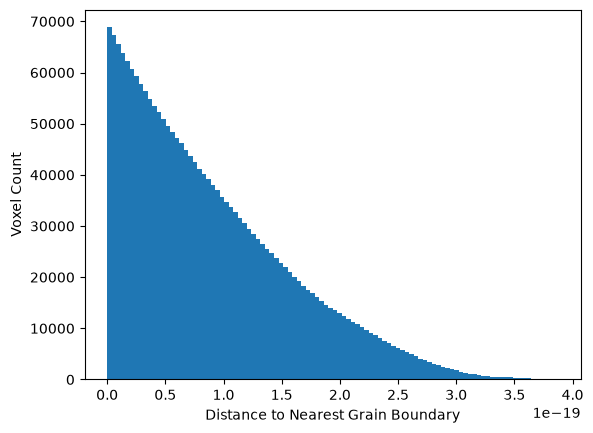

In [107]:
# Plot the resulting 2,097,152 distances directly
plt.hist(min_distance_from_GBs_array, bins=100)
plt.xlabel("Distance to Nearest Grain Boundary")
plt.ylabel("Voxel Count")
plt.show()

In [16]:
def distance_from_voxels_to_nearest_GB(seeds):
# seeds: (N, 3) array of Voronoi cell generator centers
# voxel_coords: (2097152, 3) array of voxel centers
    tree = scipy.spatial.cKDTree(seeds)

# Find the 1st nearest seed (cell owner) and k-1 nearest neighbor seeds
# k=20 covers virtually all 3D Voronoi neighbor adjacencies
    k = 20
    distances, indices = tree.query(voxel_coords_list, k=k)

# r1: distance to the voxel's own cell seed (2097152, 1)
    r1 = distances[:, 0:1]
    s1_coords = seeds[indices[:, 0]]  # (2097152, 3)

# r_j: distances to neighboring seeds (2097152, k-1)
    rj = distances[:, 1:]
    sj_coords = seeds[indices[:, 1:]]  # (2097152, k-1, 3)

# Distance between seed 1 and neighbor seeds S_j
    seed_distances = np.linalg.norm(sj_coords - s1_coords[:, np.newaxis, :], axis=2)

# Distance to each bisecting plane: d = (r_j^2 - r_1^2) / (2 * ||S_j - S_1||)
    plane_distances = (rj**2 - r1**2) / (2.0 * seed_distances)

# The shortest distance across all neighbor planes is the exact boundary distance
    min_distance_from_GBs = np.min(plane_distances, axis=1)

    return min_distance_from_GBs

In [17]:
gemini_min_distance_from_GBs = distance_from_voxels_to_nearest_GB(microstructure_1000_seeds)

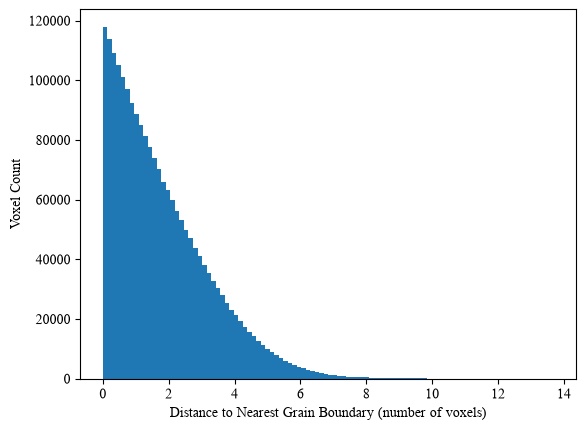

In [18]:
plt.hist(gemini_min_distance_from_GBs/(voxel_coords_list[0][0]*2), bins = 100)
plt.xlabel("Distance to Nearest Grain Boundary (number of voxels)")
plt.ylabel("Voxel Count")
plt.show()

Triaxiality distribution

In [19]:
pheno_triax = np.load('./data/pheno_triax.npy')
dislo_triax = np.load('./data/dislo_triax.npy')

In [20]:
pheno_triax_flat = pheno_triax.flatten(order = 'F')
dislo_triax_flat = dislo_triax.flatten(order = 'F')

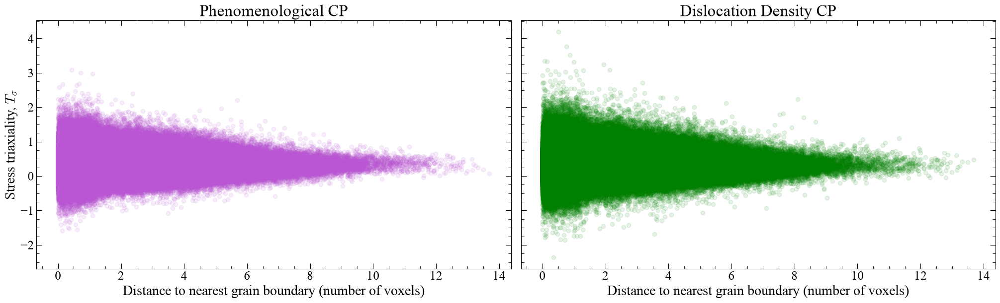

In [ ]:
from matplotlib.ticker import AutoMinorLocator
fig_gb_dist, ax_gb_dist = plt.subplots(1, 2, figsize=(20,6), sharey= True, sharex = True, constrained_layout = True)
ax_gb_dist[0].scatter(gemini_min_distance_from_GBs/(voxel_coords_list[0][0]*2), pheno_triax_flat, color = 'mediumorchid', alpha = 0.1)
ax_gb_dist[1].scatter(gemini_min_distance_from_GBs/(voxel_coords_list[0][0]*2), dislo_triax_flat, color = 'green', alpha = 0.1)

ax_gb_dist[0].set_title("Phenomenological CP", fontsize = 24)
ax_gb_dist[1].set_title("Dislocation Density CP", fontsize = 24)
ax_gb_dist[0].set_xlabel("Distance to nearest grain boundary (number of voxels)", fontsize = 20)
ax_gb_dist[1].set_xlabel("Distance to nearest grain boundary (number of voxels)", fontsize = 20)
ax_gb_dist[0].set_ylabel(r"Stress triaxiality, $T_{\sigma}$", fontsize = 20, math_fontfamily = 'cm')

ax_gb_dist[0].tick_params(which = 'both', direction = 'in', top = True, right = True, labelsize = 18)
ax_gb_dist[0].tick_params(which = 'minor', length = 4)
ax_gb_dist[0].tick_params(which = 'major', length = 8)
ax_gb_dist[1].tick_params(which = 'both', direction = 'in', top = True, right = True, labelsize = 18)
ax_gb_dist[1].tick_params(which = 'minor', length = 4)
ax_gb_dist[1].tick_params(which = 'major', length = 8)

ax_gb_dist[0].xaxis.set_minor_locator(AutoMinorLocator(4))
ax_gb_dist[0].yaxis.set_minor_locator(AutoMinorLocator(4))
ax_gb_dist[1].xaxis.set_minor_locator(AutoMinorLocator(4))
ax_gb_dist[1].yaxis.set_minor_locator(AutoMinorLocator(4))

plt.savefig("stress_triax_vals_against_gb_distance.png", dpi = 800)

Strain distribution

In [33]:
pheno_xx_strain = np.load('./data/pheno_128_xx_strain.npy')
dislo_xx_strain = np.load('./data/dislo_128_xx_strain.npy')

In [34]:
pheno_xx_strain_flat = pheno_xx_strain.flatten(order = 'F')
dislo_xx_strain_flat = dislo_xx_strain.flatten(order = 'F')

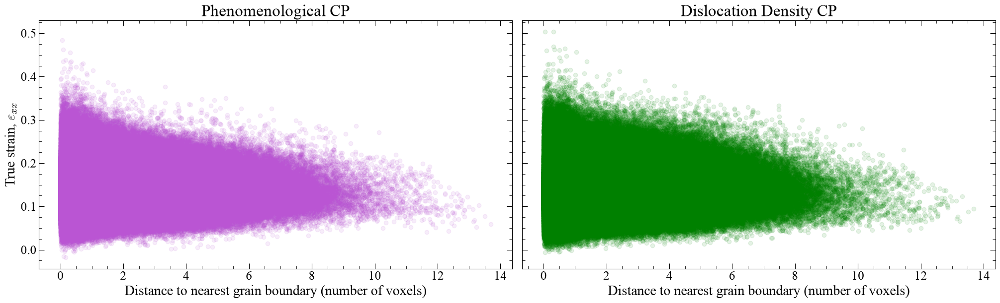

In [38]:
fig_gb_dist_2, ax_gb_dist_2 = plt.subplots(1, 2, figsize=(20,6), sharey= True, sharex = True, constrained_layout = True)
ax_gb_dist_2[0].scatter(gemini_min_distance_from_GBs/(voxel_coords_list[0][0]*2), pheno_xx_strain_flat, color = 'mediumorchid', alpha = 0.1)
ax_gb_dist_2[1].scatter(gemini_min_distance_from_GBs/(voxel_coords_list[0][0]*2), dislo_xx_strain_flat, color = 'green', alpha = 0.1)

ax_gb_dist_2[0].set_title("Phenomenological CP", fontsize = 24)
ax_gb_dist_2[1].set_title("Dislocation Density CP", fontsize = 24)
ax_gb_dist_2[0].set_xlabel("Distance to nearest grain boundary (number of voxels)", fontsize = 20)
ax_gb_dist_2[1].set_xlabel("Distance to nearest grain boundary (number of voxels)", fontsize = 20)
ax_gb_dist_2[0].set_ylabel(r"True strain, $\varepsilon_{xx}$", fontsize = 20, math_fontfamily = 'cm')

ax_gb_dist_2[0].tick_params(which = 'both', direction = 'in', top = True, right = True, labelsize = 18)
ax_gb_dist_2[0].tick_params(which = 'minor', length = 4)
ax_gb_dist_2[0].tick_params(which = 'major', length = 8)
ax_gb_dist_2[1].tick_params(which = 'both', direction = 'in', top = True, right = True, labelsize = 18)
ax_gb_dist_2[1].tick_params(which = 'minor', length = 4)
ax_gb_dist_2[1].tick_params(which = 'major', length = 8)

ax_gb_dist_2[0].xaxis.set_minor_locator(AutoMinorLocator(4))
ax_gb_dist_2[0].yaxis.set_minor_locator(AutoMinorLocator(4))
ax_gb_dist_2[1].xaxis.set_minor_locator(AutoMinorLocator(4))
ax_gb_dist_2[1].yaxis.set_minor_locator(AutoMinorLocator(4))

plt.savefig("strain_vals_against_gb_distance.png", dpi = 800)

# SciPy

In [3]:
GBs = scipy.spatial.Delaunay(points = microstructure_1000_seeds)
GBs_xy = scipy.spatial.Delaunay(points = microstructure_1000_seeds_xy)

In [4]:
GBs.simplices, GBs_xy.simplices

(array([[801, 290, 645, 123],
        [974,  59, 929, 515],
        [198, 644,  76, 219],
        ...,
        [626, 122, 537, 454],
        [626, 261, 537, 454],
        [626, 261, 122, 454]], shape=(6356, 4), dtype=int32),
 array([[364, 186, 938],
        [109, 925, 194],
        [404, 174, 642],
        ...,
        [188, 144, 124],
        [633, 188, 475],
        [ 51, 188, 633]], shape=(1976, 3), dtype=int32))

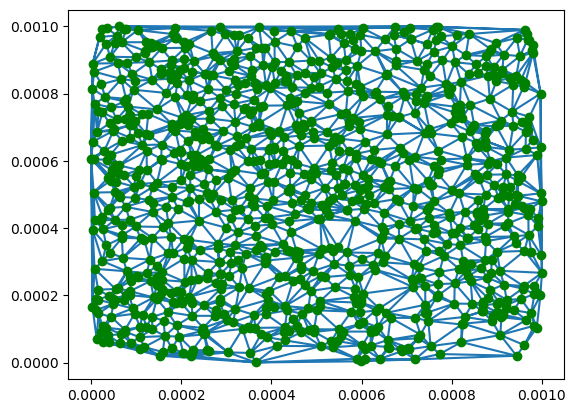

In [5]:
%matplotlib inline
plt.triplot(microstructure_1000_seeds[:,0], microstructure_1000_seeds[:,1], GBs_xy.simplices)
plt.scatter(microstructure_1000_seeds[:,0], microstructure_1000_seeds[:,1], marker = 'o', color = 'g')
plt.show()

In [14]:
GBs_vor = scipy.spatial.Voronoi(points = microstructure_1000_seeds)

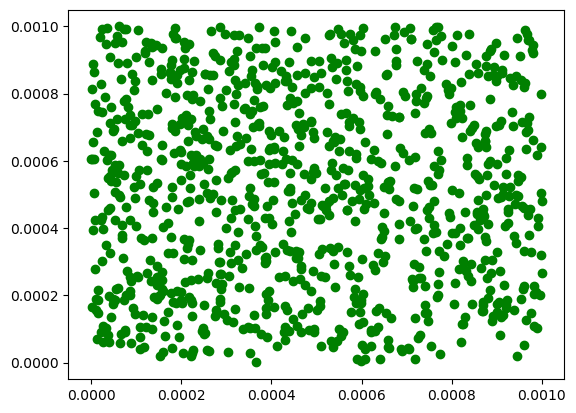

In [11]:
%matplotlib inline
GBs_vor.vertices
#plt.triplot(microstructure_1000_seeds[:,0], microstructure_1000_seeds[:,1], GBs_vor.vertices)
plt.scatter(microstructure_1000_seeds[:,0], microstructure_1000_seeds[:,1], marker = 'o', color = 'g')
plt.show()

In [15]:
GBs_vor.vertices

array([[ 4.40944745e-04,  1.24617018e-03,  4.54220005e-03],
       [ 1.14086083e-04,  1.09057341e-03, -5.52451765e-06],
       [ 9.55161141e-05,  1.80369915e-04,  1.19582452e-03],
       ...,
       [ 2.96263873e-04,  8.44961942e-04,  1.23062660e-04],
       [ 3.30299199e-04,  8.48006802e-04,  1.29438324e-04],
       [ 2.97328229e-04,  8.42259650e-04,  1.24700294e-04]],
      shape=(6356, 3))

ValueError: Voronoi diagram is not 2-D

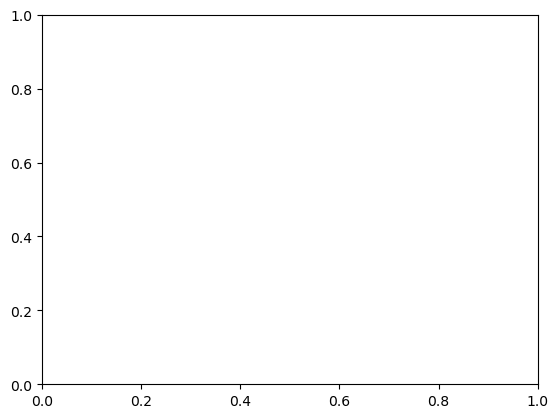

In [18]:
fig = scipy.spatial.voronoi_plot_2d(GBs_vor)
plt.show()

In [47]:
test_list = [128,128,128]
test_list.extend([3,3])
print(test_list)

[128, 128, 128, 3, 3]
